# 03 经济趋势（MySQL + Python 可视化）

**数据源**：MySQL `olist` 库
**分析逻辑**：直接执行 `analysis_code/03_economic_trends.sql`，Python 只负责取数 + 画图
**口径**：
- GMV = 有效订单（排除 `canceled/unavailable`）支付金额之和（含运费）
- 履约率 / 取消率的分母是**全部订单**


In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 找到项目根（含 analysis_code/ 的目录），兼容从 notebooks/ 或项目根启动
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "analysis_code").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "notebooks"))
import db

# 先设 seaborn 主题，再设中文字体（顺序不能反）
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120

print("project root:", PROJECT_ROOT)
print("sql dir:", db.SQL_DIR)

project root: C:\Users\iiLI\Desktop\1
sql dir: C:\Users\iiLI\Desktop\1\analysis_code


## 1. 执行 SQL

In [2]:
results = db.run_sql_file(db.SQL_DIR / "03_economic_trends.sql")
monthly, quality = results[0], results[1]

print("monthly:", monthly.shape)
print("quality:", quality.shape)
monthly

monthly: (20, 8)
quality: (20, 7)


,month,order_count,gmv,aov,gmv_mom_pct,running_gmv,order_count_mom_pct,aov_mom_pct
0,2017-01,787,137006.76,174.09,NaN,137006.76,NaN,NaN
1,2017-02,1718,283621.94,165.09,107.01,420628.70,118.30,-5.17
2,2017-03,2617,425656.40,162.65,50.08,846285.10,52.33,-1.48
3,2017-04,2377,405988.38,170.80,-4.62,1252273.48,-9.17,5.01
4,2017-05,3640,582926.16,160.14,43.58,1835199.64,53.13,-6.24
5,2017-06,3205,499827.47,155.95,-14.26,2335027.11,-11.95,-2.62
6,2017-07,3946,578858.58,146.70,15.81,2913885.69,23.12,-5.93
7,2017-08,4272,662071.77,154.98,14.38,3575957.46,8.26,5.64
8,2017-09,4227,717195.22,169.67,8.33,4293152.68,-1.05,9.48
9,2017-10,4547,764785.28,168.20,6.64,5057937.96,7.57,-0.87


## 2. 图 1：月度 GMV / 累计 GMV / 订单量 / 客单价

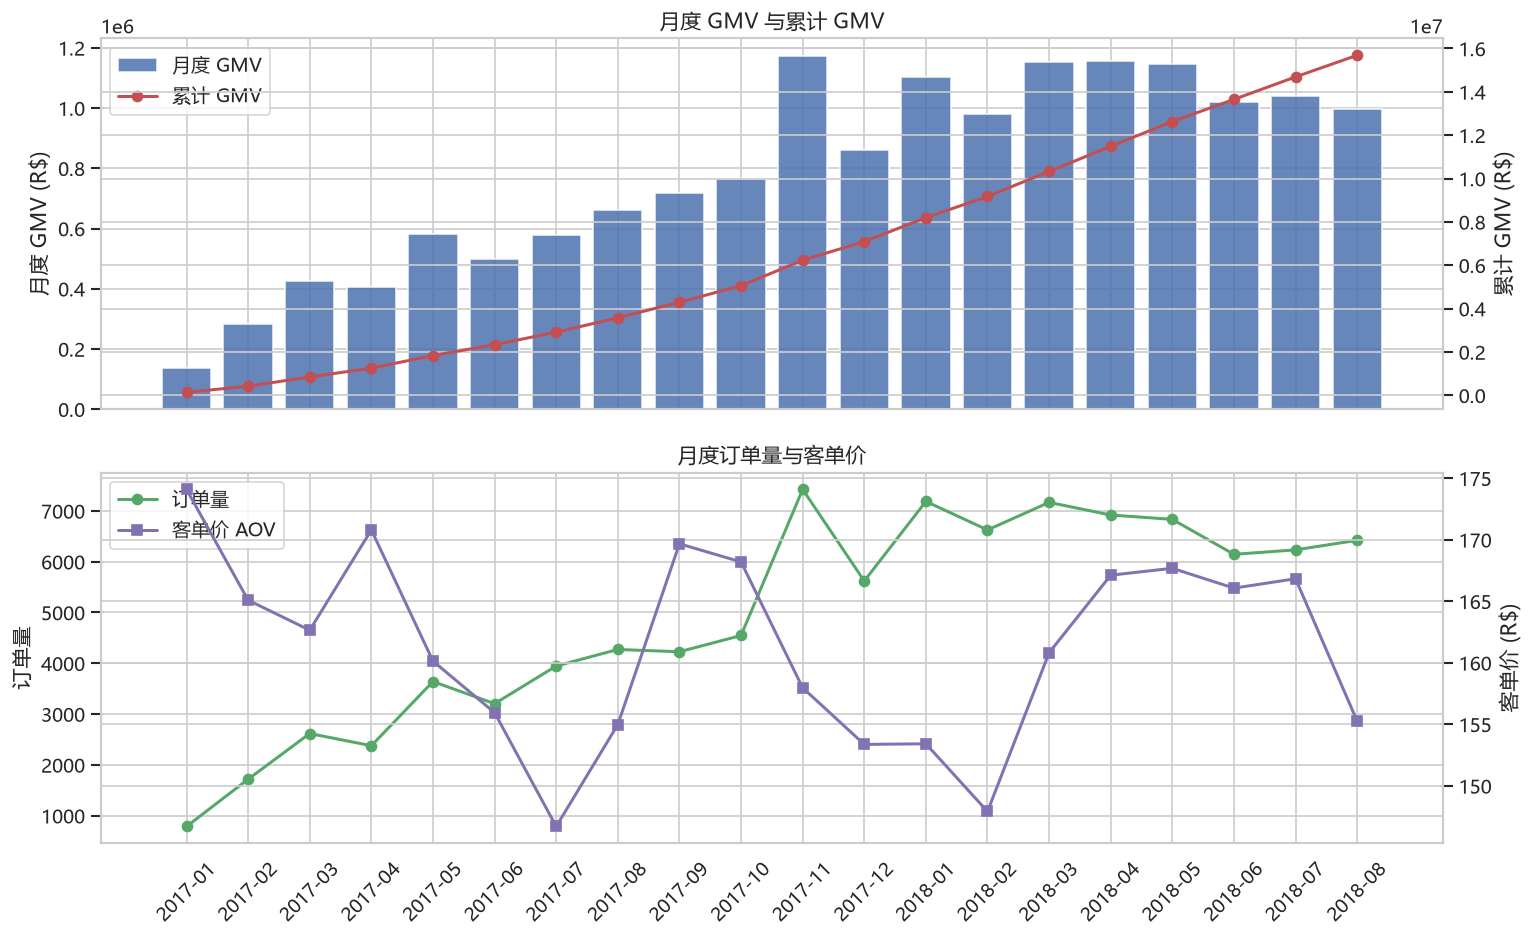

In [3]:
x = monthly["month"]

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

ax = axes[0]
ax.bar(x, monthly["gmv"], color="#4C72B0", alpha=0.85, label="月度 GMV")
ax.set_ylabel("月度 GMV (R$)")
ax.tick_params(axis="x", rotation=45)
ax2 = ax.twinx()
ax2.plot(x, monthly["running_gmv"], color="#C44E52", marker="o", lw=1.8, label="累计 GMV")
ax2.set_ylabel("累计 GMV (R$)")
ax.set_title("月度 GMV 与累计 GMV")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")

ax = axes[1]
ax.plot(x, monthly["order_count"], color="#55A868", marker="o", lw=1.8, label="订单量")
ax.set_ylabel("订单量")
ax.tick_params(axis="x", rotation=45)
ax2 = ax.twinx()
ax2.plot(x, monthly["aov"], color="#8172B2", marker="s", lw=1.8, label="客单价 AOV")
ax2.set_ylabel("客单价 (R$)")
ax.set_title("月度订单量与客单价")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")

plt.tight_layout()
plt.show()

### 观察
- GMV 整体趋势是上升
- 2017-11 有峰值，说明是单月脉冲。
- 增长主要由客单价驱动


## 3. 图 2：履约率与取消率

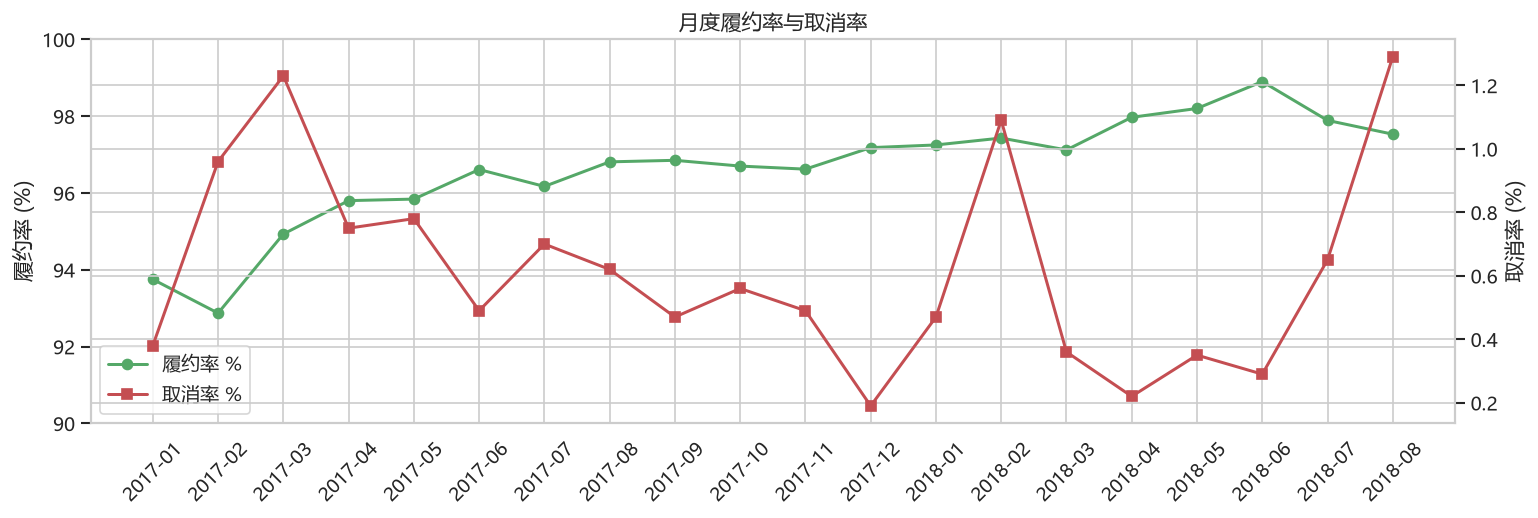

In [4]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(quality["month"], quality["fulfillment_rate_pct"], color="#55A868", marker="o", lw=1.8, label="履约率 %")
ax.set_ylabel("履约率 (%)")
ax.set_ylim(90, 100)
ax.tick_params(axis="x", rotation=45)

ax2 = ax.twinx()
ax2.plot(quality["month"], quality["cancel_rate_pct"], color="#C44E52", marker="s", lw=1.8, label="取消率 %")
ax2.set_ylabel("取消率 (%)")

ax.set_title("月度履约率与取消率")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="lower left")

plt.tight_layout()
plt.show()

### 观察
- 履约率整体偏稳定小幅上升，在2017年2月份明显降低
- 取消率高峰和 GMV 高峰无关
